In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# Shared colors and helper functions used by the later analysis cells.
#science_colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#F0E442']

def p_to_label(p_value):
    if p_value < 0.001:
        return '***'
    if p_value < 0.01:
        return '**'
    if p_value < 0.05:
        return '*'
    return 'n.s.'


def paired_comparison(x, y, alpha=0.05):
    """Select a paired t-test or Wilcoxon test from difference normality."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    normality_p = stats.shapiro(x - y).pvalue
    if normality_p > alpha:
        result = stats.ttest_rel(x, y)
        test_name = 'paired t-test'
    else:
        result = stats.wilcoxon(x, y, alternative='two-sided', mode='auto')
        test_name = 'paired Wilcoxon signed-rank test'
    return {'test': test_name, 'normality_p': normality_p,
            'statistic': result.statistic, 'raw_p': result.pvalue, 'n': len(x)}

def draw_significance(ax, x1, x2, y, h, p_value):
    """Draw a theta-gamma-style bracket with a p-derived label."""
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y],
            lw=1.2, color='#333333', clip_on=False)
    if p_value < 0.05:
        ax.text((x1 + x2) / 2, y + h - 6, p_to_label(p_value),
                ha='center', va='bottom', color='#333333')
    else:
        ax.text((x1 + x2) / 2, y + h - 1, p_to_label(p_value),
                ha='center', va='bottom', color='#333333')


def ploterrorbar(data, ebar='SD', facecolor=None):
    """Plot condition means with SD or SE error bars."""
    fields = list(data.keys())
    values = [np.asarray(data[field], dtype=float) for field in fields]
    means = np.array([np.mean(v) for v in values])
    errors = np.array([
        np.std(v, ddof=1) if ebar == 'SD' else np.std(v, ddof=1) / np.sqrt(len(v))
        for v in values
    ])
    if facecolor is None:
        facecolor = np.array([224, 236, 244]) / 255
    fig, ax = plt.subplots(figsize=(2.4, 2.0))
    x = np.arange(len(fields))
    ax.bar(x, means, width=0.7, color=facecolor, alpha=0.8,
           edgecolor='black', linewidth=1)
    ax.errorbar(x, means, yerr=errors, fmt='.k', linewidth=1, capsize=5)
    rng = np.random.default_rng(20260729)
    for position, field_values in zip(x, values):
        jitter = rng.uniform(-0.16, 0.16, size=len(field_values))
        ax.scatter(position + jitter, field_values, s=12, color=facecolor,
                   edgecolor='white', linewidth=0.3, alpha=0.75, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(fields)
    return means, errors, fig, ax

def plot_grouped_comparison(data_bio, data_hard, save_path=None, x_labels=None):
    """Plot Bio and BNC means side by side for each condition."""
    fields = list(data_bio.keys())
    means = np.array([
        [np.mean(data_bio[field]) for field in fields],
        [np.mean(data_hard[field]) for field in fields],
    ])
    errors = np.array([
        [np.std(data_bio[field], ddof=1) for field in fields],
        [np.std(data_hard[field], ddof=1) for field in fields],
    ])
    x = np.arange(len(fields))
    width = 0.3
    fig, ax = plt.subplots(figsize=(3.2, 2.0))
    for i, (label, color) in enumerate([('Bio', science_colors[0]), ('BNC', science_colors[1])]):
        positions = x + (i - 0.5) * width
        ax.bar(positions, means[i], width, color=color, alpha=0.8,
               edgecolor='black', linewidth=1, label=label)
        ax.errorbar(positions, means[i], yerr=errors[i], fmt='none',
                    color='black', capsize=4, linewidth=1)
        rng = np.random.default_rng(20260729 + i)
        source = data_bio if i == 0 else data_hard
        for position, field in zip(positions, fields):
            field_values = np.asarray(source[field], dtype=float)
            jitter = rng.uniform(-0.08, 0.08, size=len(field_values))
            ax.scatter(position + jitter, field_values, s=10, color=color,
                       edgecolor='white', linewidth=0.25, alpha=0.7, zorder=3)
    ax.set_ylabel('Performance (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels if x_labels is not None else fields)
    ax.set_ylim(0, 110)
    ax.legend(frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    return fig, ax, (means, errors)

def _holm_adjust(p_values):
    """Holm family-wise error correction without external dependencies."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty_like(p_values)
    running_max = 0.0
    m = len(p_values)
    for rank, index in enumerate(order):
        running_max = max(running_max, (m - rank) * p_values[index])
        adjusted_sorted[rank] = min(running_max, 1.0)
    adjusted = np.empty_like(p_values)
    adjusted[order] = adjusted_sorted
    return adjusted

def _repeated_measures_anova(groups):
    """One-factor repeated-measures ANOVA for a complete paired matrix."""
    matrix = np.column_stack(groups)
    n_subjects, n_conditions = matrix.shape
    grand_mean = np.mean(matrix)
    ss_total = np.sum((matrix - grand_mean) ** 2)
    ss_subject = n_conditions * np.sum((np.mean(matrix, axis=1) - grand_mean) ** 2)
    ss_condition = n_subjects * np.sum((np.mean(matrix, axis=0) - grand_mean) ** 2)
    ss_error = ss_total - ss_subject - ss_condition
    df_condition = n_conditions - 1
    df_error = (n_subjects - 1) * (n_conditions - 1)
    f_stat = (ss_condition / df_condition) / (ss_error / df_error)
    p_value = stats.f.sf(f_stat, df_condition, df_error)
    eta_p2 = ss_condition / (ss_condition + ss_error)
    return f_stat, p_value, df_condition, df_error, eta_p2

def compare_three_groups(group1, group2, group3, group_names=None,
                         alpha=0.05, test_type='auto', verbose=True):
    """Adaptive paired analysis: RM-ANOVA or Friedman plus Holm post-hoc."""
    names = group_names or ['Group1', 'Group2', 'Group3']
    groups = [np.asarray(g, dtype=float).reshape(-1) for g in (group1, group2, group3)]
    if len({len(group) for group in groups}) != 1:
        raise ValueError('Paired groups must have the same number of observations')
    complete = ~np.any(np.column_stack([np.isnan(group) for group in groups]), axis=1)
    groups = [group[complete] for group in groups]
    if len(groups[0]) < 3:
        raise ValueError('At least 3 complete paired observations are required')

    shapiro_groups = [stats.shapiro(group) for group in groups]
    pairs = [(0, 1), (0, 2), (1, 2)]
    shapiro_differences = [stats.shapiro(groups[i] - groups[j]) for i, j in pairs]
    normal_groups = all(np.isfinite(test.pvalue) and test.pvalue > alpha for test in shapiro_groups)
    normal_differences = all(
        np.isfinite(test.pvalue) and test.pvalue > alpha for test in shapiro_differences
    )
    use_parametric = normal_groups and normal_differences

    if verbose:
        print('\n' + '=' * 68)
        print('PAIRED THREE-PHASE STATISTICAL ANALYSIS')
        print(f'Analysis unit: seed mean; paired n = {len(groups[0])}')
        print('\nShapiro-Wilk normality tests for the three groups:')
        for name, test in zip(names, shapiro_groups):
            decision = 'normal' if test.pvalue > alpha else 'not normal'
            print(f'  {name}: W={test.statistic:.4f}, p={test.pvalue:.6g} -> {decision}')
        print('Shapiro-Wilk tests for paired differences (RM-ANOVA assumption):')
        for (i, j), test in zip(pairs, shapiro_differences):
            decision = 'normal' if test.pvalue > alpha else 'not normal'
            print(f'  {names[i]} - {names[j]}: W={test.statistic:.4f}, ' 
                  f'p={test.pvalue:.6g} -> {decision}')

    if use_parametric:
        omnibus = _repeated_measures_anova(groups)
        statistic, p_value, df1, df2, effect_size = omnibus
        test_name = 'one-factor repeated-measures ANOVA'
        posthoc_name = 'paired t-tests with Holm correction'
        posthoc_results = [stats.ttest_rel(groups[i], groups[j]) for i, j in pairs]
        if verbose:
            print(f'\nAll normality checks passed: use {test_name}.')
            print(f'  F({df1}, {df2})={statistic:.4f}, p={p_value:.6g}, ' 
                  f'partial eta-squared={effect_size:.4f}')
    else:
        omnibus = stats.friedmanchisquare(*groups)
        statistic, p_value = omnibus.statistic, omnibus.pvalue
        test_name = 'Friedman test'
        posthoc_name = 'paired Wilcoxon signed-rank tests with Holm correction'
        posthoc_results = [
            stats.wilcoxon(groups[i], groups[j], alternative='two-sided', mode='auto')
            for i, j in pairs
        ]
        effect_size = statistic / (len(groups[0]) * (len(groups) - 1))
        if verbose:
            print(f'\nAt least one normality check failed: use {test_name}.')
            print(f'  chi-square={statistic:.4f}, p={p_value:.6g}, Kendall W={effect_size:.4f}')

    raw_p = np.array([result.pvalue for result in posthoc_results])
    adjusted_p = _holm_adjust(raw_p)
    if verbose:
        print(f'\nPost-hoc: {posthoc_name}')
        for (i, j), result, p_raw, p_adjusted in zip(pairs, posthoc_results, raw_p, adjusted_p):
            print(f'  {names[i]} vs {names[j]}: statistic={result.statistic:.4f}, ' 
                  f'raw p={p_raw:.6g}, Holm-adjusted p={p_adjusted:.6g}')
        print('=' * 68)

    return {
        'test': test_name, 'statistic': statistic, 'p_value': p_value,
        'effect_size': effect_size, 'normal_groups': normal_groups,
        'normal_differences': normal_differences, 'raw_posthoc_p': raw_p,
        'adjusted_posthoc_p': adjusted_p, 'n': len(groups[0]),
    }

# ==========================================
# 1. Global font and axis styling
# ==========================================
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams.update({'svg.fonttype': 'none', 'pdf.fonttype': 42})  # Editable vector text
mpl.rcParams['axes.edgecolor'] = 'black'  # Use black axis borders
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.color'] = 'black'
mpl.rcParams['ytick.color'] = 'black'

# Point both x-axis and y-axis ticks inward
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

# --- Explicit tick settings to ensure consistent rendering ---
mpl.rcParams['xtick.bottom'] = True        # Enable bottom ticks
mpl.rcParams['ytick.left'] = True          # Enable left ticks
mpl.rcParams['xtick.major.width'] = 1.2    # Match tick width to axis width
mpl.rcParams['ytick.major.width'] = 1.2
mpl.rcParams['xtick.major.size'] = 4.0     # Major tick length
mpl.rcParams['ytick.major.size'] = 4.0

plt.rcParams.update({
    'font.size': 8+5,          # Default text
    'axes.titlesize': 8+5,     # Title
    'axes.labelsize': 8+5,     # Axis labels
    'xtick.labelsize': 7+5,    # X-axis tick labels
    'ytick.labelsize': 7+5,    # Y-axis tick labels
    'legend.fontsize': 7+5,    # Legend
    'figure.titlesize': 9+5,   # Figure-level title
})

color_bio = '#5C8EBC'  # Muted blue
color_hw = '#E58A46'   # Warm orange

# ==========================================
# 2. Load data and handle NaN values
# ==========================================
filedir0 = './figures/'
bio_file = './data/Perf_Bio_python.npz'
hard_file = './data/Perf_hard_python.npz'

#bio_file = '../Simulations/Perf_Bio_python.npz' #'../Simulations/Perf_flat_hard_python.npz'#'./data/Perf_bio_python_5seeds.npz'
#hard_file = '../Simulations/Perf_hard_python.npz'  #'./data/Perf_hard_python_5seeds.npz'

try:
    bio_archive = np.load(bio_file)
    hard_archive = np.load(hard_file)
    field_names = tuple(bio_archive.files)
    if field_names != tuple(hard_archive.files):
        raise ValueError('Bio and Hard NPZ files must contain the same fields')
except Exception as e:
    print(f"Failed to load data: {e}")
    exit()

data_bio = [np.asarray(bio_archive[f], dtype=float).flatten() for f in field_names[:3]]
data_hw = [np.asarray(hard_archive[f], dtype=float).flatten() for f in field_names[:3]]

data_bio = [d[~np.isnan(d)] for d in data_bio]
data_hw = [d[~np.isnan(d)] for d in data_hw]

# Use paired seed means for inference; the 50 raw values remain visible in the plot.
bio_seed_means = {field: np.nanmean(np.asarray(bio_archive[field], dtype=float), axis=1)
                  for field in ('Baseline', 'Before', 'After')}
hard_seed_means = {field: np.nanmean(np.asarray(hard_archive[field], dtype=float), axis=1)
                  for field in ('Baseline', 'Before', 'After')}

comparison_results = [
    paired_comparison(bio_seed_means['After'], hard_seed_means['After']),
]



In [2]:
# 3. Bio and Hard: paired statistical analysis of Baseline, Before, and After
# ==========================================
# Each row represents one independent seed; average the 10 runs within each seed first.
# The plot still shows all 50 points, while inference uses the five paired seed means.
data_bio_seed_means = {
    field: np.mean(np.asarray(bio_archive[field], dtype=float), axis=1)
    for field in ('Baseline', 'Before', 'After')
}

results_bio = compare_three_groups(
    data_bio_seed_means['Baseline'],
    data_bio_seed_means['Before'],
    data_bio_seed_means['After'],
    group_names=['Baseline', 'Before', 'After'],
    alpha=0.05,
    test_type='auto',
    verbose=True,
)

data_hard_seed_means = {
    field: np.mean(np.asarray(hard_archive[field], dtype=float), axis=1)
    for field in ('Baseline', 'Before', 'After')
}

results_hard = compare_three_groups(
    data_hard_seed_means['Baseline'],
    data_hard_seed_means['Before'],
    data_hard_seed_means['After'],
    group_names=['Baseline', 'Before', 'After'],
    alpha=0.05,
    test_type='auto',
    verbose=True,
)


PAIRED THREE-PHASE STATISTICAL ANALYSIS
Analysis unit: seed mean; paired n = 5

Shapiro-Wilk normality tests for the three groups:
  Baseline: W=0.9420, p=0.679904 -> normal
  Before: W=0.8774, p=0.29765 -> normal
  After: W=0.9155, p=0.501061 -> normal
Shapiro-Wilk tests for paired differences (RM-ANOVA assumption):
  Baseline - Before: W=0.9794, p=0.931152 -> normal
  Baseline - After: W=0.9475, p=0.719602 -> normal
  Before - After: W=0.9489, p=0.729347 -> normal

All normality checks passed: use one-factor repeated-measures ANOVA.
  F(2, 8)=44.7297, p=4.54011e-05, partial eta-squared=0.9179

Post-hoc: paired t-tests with Holm correction
  Baseline vs Before: statistic=-2.5812, raw p=0.0612469, Holm-adjusted p=0.0612469
  Baseline vs After: statistic=-12.3212, raw p=0.000249291, Holm-adjusted p=0.000747873
  Before vs After: statistic=-5.3234, raw p=0.00599177, Holm-adjusted p=0.0119835

PAIRED THREE-PHASE STATISTICAL ANALYSIS
Analysis unit: seed mean; paired n = 5

Shapiro-Wilk no

In [3]:
hard_pvalue = results_hard['adjusted_posthoc_p'][2]
bio_pvalue =  results_bio['adjusted_posthoc_p'][2]
print('hard_pvalue:',hard_pvalue)
print('bio_pvalue:',bio_pvalue)
print(comparison_results[0]['raw_p'])



hard_pvalue: 0.006770992129136043
bio_pvalue: 0.011983534260405262
0.6418876022964817


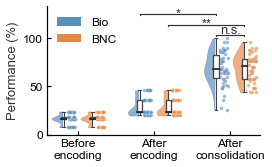

In [4]:
# ==========================================
# 4. Raincloud plot: left half-violin, central box, and right-side raw points
# ==========================================
fig, ax = plt.subplots(figsize=(4.6*0.86, 2.52))

pos_bio = [1, 3, 5]
pos_hw = [1.75, 3.75, 5.75]

# --- Cloud: retain only the left half of each violin ---
vp_bio = ax.violinplot(data_bio, positions=pos_bio, widths=0.62, showextrema=False)
for pc, position in zip(vp_bio['bodies'], pos_bio):
    vertices = pc.get_paths()[0].vertices
    vertices[:, 0] = np.minimum(vertices[:, 0], position - 0.04)
    pc.set_facecolor(color_bio)
    pc.set_edgecolor(color_bio)
    pc.set_linewidth(0.8)
    pc.set_alpha(0.68)
    pc.set_zorder(1)

vp_hw = ax.violinplot(data_hw, positions=pos_hw, widths=0.62, showextrema=False)
for pc, position in zip(vp_hw['bodies'], pos_hw):
    vertices = pc.get_paths()[0].vertices
    vertices[:, 0] = np.minimum(vertices[:, 0], position - 0.04)
    pc.set_facecolor(color_hw)
    pc.set_edgecolor(color_hw)
    pc.set_linewidth(0.8)
    pc.set_alpha(0.68)
    pc.set_zorder(1)

# --- Rain: place all raw points to the right of each box (50 per phase and group) ---
rng = np.random.default_rng(20260729)
for position, values in zip(pos_bio, data_bio):
    jitter = rng.uniform(0.10, 0.31, size=len(values))
    ax.scatter(position + jitter, values, s=13, color=color_bio,
               edgecolor='white', linewidth=0.3, alpha=0.62, zorder=2)
for position, values in zip(pos_hw, data_hw):
    jitter = rng.uniform(0.10, 0.31, size=len(values))
    ax.scatter(position + jitter, values, s=13, color=color_hw,
               edgecolor='white', linewidth=0.3, alpha=0.62, zorder=2)

# --- Central box plot: use a white fill and high z-order to prevent occlusion ---
box_width = 0.14
box_kwargs = dict(
    widths=box_width, 
    patch_artist=True,
    whis=(0, 100),  # Extend whiskers across the full data range
    showfliers=False,
    boxprops=dict(facecolor='white', linewidth=1.3, zorder=4),
    medianprops=dict(color='#222222', linewidth=1.7, zorder=5), 
    whiskerprops=dict(color='#444444', linewidth=1.1, zorder=4), 
    capprops=dict(color='#444444', linewidth=1.1, zorder=4),
    flierprops=dict(marker='')
)

bp_bio = ax.boxplot(data_bio, positions=pos_bio, **box_kwargs)
for box in bp_bio['boxes']:
    box.set_facecolor('white')
    box.set_edgecolor('#444444')

bp_hw = ax.boxplot(data_hw, positions=pos_hw, **box_kwargs)
for box in bp_hw['boxes']:
    box.set_facecolor('white')
    box.set_edgecolor('#444444')

# ==========================================
#  Axis and legend styling
# ==========================================
ax.set_ylabel('Performance (%)',  color='#333333')

ax.set_xticks([1.375, 3.375, 5.375])
ax.set_xticklabels(['Before\nencoding', 'After\nencoding', 'After\nconsolidation'])
# Position the three brackets dynamically above the highest observation.
data_top = max(np.max(values) for values in data_bio + data_hw)
bracket_step = 11.0
bracket_height = 1.2
y_consolidation = data_top + 2.0
y_bnc = y_consolidation + bracket_step
y_bio = y_bnc + bracket_step

# Lowest: Bio versus BNC after consolidation; middle/top: within-method phase changes.
draw_significance(ax, pos_bio[1], pos_bio[2], y_bio, bracket_height,
                  bio_pvalue)
draw_significance(ax, pos_hw[1], pos_hw[2], y_bnc, bracket_height,
                  hard_pvalue)
draw_significance(ax, pos_bio[2], pos_hw[2], y_consolidation, bracket_height,
                  comparison_results[0]['raw_p'])


ax.set_ylim(0, y_bio + 9.0)
ax.set_xlim(0.55, 6.15)
ax.set_yticks([0, 50, 100])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y')
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_bio, edgecolor='none', label='Bio'),
                   Patch(facecolor=color_hw, edgecolor='none', label='BNC')]
ax.legend(handles=legend_elements, loc='upper left', frameon=False)

plt.tight_layout()

save_path = os.path.join(filedir0, 'performance_raincloud_final_BIO.svg')
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, bbox_inches='tight')
plt.savefig(os.path.join(filedir0, 'performance_raincloud_final_BIO.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(filedir0, 'performance_raincloud_final_BIO.png'), dpi=600, bbox_inches='tight')
plt.savefig(os.path.join(filedir0, 'performance_raincloud_final_BIO.tiff'), dpi=600, bbox_inches='tight')
plt.show()


In [5]:
filedir0

'./figures/'

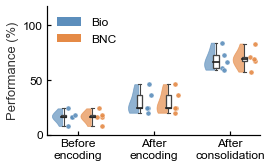

Seed-mean raincloud: one point per seed; n=5 seeds, 10 inputs averaged per seed.


In [6]:
# ==========================================
# 5. Seed-mean raincloud plot (one point per seed)
# ==========================================
# Average the 10 inputs within each seed, retaining five seed means per phase.
seed_plot_fields = ('Baseline', 'Before', 'After')
data_bio_seed_plot = [bio_seed_means[field] for field in seed_plot_fields]
data_bnc_seed_plot = [hard_seed_means[field] for field in seed_plot_fields]

fig_seed, ax_seed = plt.subplots(figsize=(4.6 * 0.86, 2.52))

pos_bio_seed = [1, 3, 5]
pos_bnc_seed = [1.75, 3.75, 5.75]

# Cloud: retain only the left half of each violin.
vp_bio_seed = ax_seed.violinplot(
    data_bio_seed_plot, positions=pos_bio_seed, widths=0.62, showextrema=False
)
for pc, position in zip(vp_bio_seed['bodies'], pos_bio_seed):
    vertices = pc.get_paths()[0].vertices
    vertices[:, 0] = np.minimum(vertices[:, 0], position - 0.04)
    pc.set_facecolor(color_bio)
    pc.set_edgecolor(color_bio)
    pc.set_linewidth(0.8)
    pc.set_alpha(0.68)
    pc.set_zorder(1)

vp_bnc_seed = ax_seed.violinplot(
    data_bnc_seed_plot, positions=pos_bnc_seed, widths=0.62, showextrema=False
)
for pc, position in zip(vp_bnc_seed['bodies'], pos_bnc_seed):
    vertices = pc.get_paths()[0].vertices
    vertices[:, 0] = np.minimum(vertices[:, 0], position - 0.04)
    pc.set_facecolor(color_hw)
    pc.set_edgecolor(color_hw)
    pc.set_linewidth(0.8)
    pc.set_alpha(0.68)
    pc.set_zorder(1)

# Rain: display five seed means for each phase and method.
rng_seed = np.random.default_rng(20260802)
for position, values in zip(pos_bio_seed, data_bio_seed_plot):
    jitter = rng_seed.uniform(0.10, 0.31, size=len(values))
    ax_seed.scatter(
        position + jitter, values, s=25, color=color_bio,
        edgecolor='white', linewidth=0.4, alpha=0.90, zorder=3
    )
for position, values in zip(pos_bnc_seed, data_bnc_seed_plot):
    jitter = rng_seed.uniform(0.10, 0.31, size=len(values))
    ax_seed.scatter(
        position + jitter, values, s=25, color=color_hw,
        edgecolor='white', linewidth=0.4, alpha=0.90, zorder=3
    )

# Central box plots summarize the same five seed means.
seed_box_kwargs = dict(
    widths=0.14,
    patch_artist=True,
    whis=(0, 100),
    showfliers=False,
    boxprops=dict(facecolor='white', linewidth=1.3, zorder=4),
    medianprops=dict(color='#222222', linewidth=1.7, zorder=5),
    whiskerprops=dict(color='#444444', linewidth=1.1, zorder=4),
    capprops=dict(color='#444444', linewidth=1.1, zorder=4),
    flierprops=dict(marker='')
)

bp_bio_seed = ax_seed.boxplot(
    data_bio_seed_plot, positions=pos_bio_seed, **seed_box_kwargs
)
for box in bp_bio_seed['boxes']:
    box.set_facecolor('white')
    box.set_edgecolor('#444444')

bp_bnc_seed = ax_seed.boxplot(
    data_bnc_seed_plot, positions=pos_bnc_seed, **seed_box_kwargs
)
for box in bp_bnc_seed['boxes']:
    box.set_facecolor('white')
    box.set_edgecolor('#444444')

# Reuse the three Holm-adjusted comparisons calculated from the same seed means.
ax_seed.set_ylabel('Performance (%)', color='#333333')
ax_seed.set_xticks([1.375, 3.375, 5.375])
ax_seed.set_xticklabels([
    'Before\nencoding', 'After\nencoding', 'After\nconsolidation'
])

seed_data_top = max(np.max(values) for values in data_bio_seed_plot + data_bnc_seed_plot)
seed_bracket_step = 11.0
seed_bracket_height = 1.2
seed_y_consolidation = seed_data_top + 2.0
seed_y_bnc = seed_y_consolidation + seed_bracket_step
seed_y_bio = seed_y_bnc + seed_bracket_step

#draw_significance(
#    ax_seed, pos_bio_seed[1], pos_bio_seed[2], seed_y_bio,
#    seed_bracket_height, comparison_results[0]['adjusted_p']
#)
#draw_significance(
#    ax_seed, pos_bnc_seed[1], pos_bnc_seed[2], seed_y_bnc,
#    seed_bracket_height, comparison_results[1]['adjusted_p']
#)
#draw_significance(
#    ax_seed, pos_bio_seed[2], pos_bnc_seed[2], seed_y_consolidation,
#    seed_bracket_height, comparison_results[2]['adjusted_p']
#)

draw_significance(ax, pos_bio[1], pos_bio[2], y_bio, bracket_height,
                  bio_pvalue)
draw_significance(ax, pos_hw[1], pos_hw[2], y_bnc, bracket_height,
                  hard_pvalue)
draw_significance(ax, pos_bio[2], pos_hw[2], y_consolidation, bracket_height,
                  comparison_results[0]['raw_p'])

ax_seed.set_ylim(0, seed_y_bio + 9.0)
ax_seed.set_xlim(0.55, 6.15)
ax_seed.set_yticks([0, 50, 100])
ax_seed.spines['top'].set_visible(False)
ax_seed.spines['right'].set_visible(False)
ax_seed.tick_params(axis='y')
ax_seed.legend(handles=legend_elements, loc='upper left', frameon=False)

plt.tight_layout()

seed_output = os.path.join(filedir0, 'performance_raincloud_seed_means_BIO')
os.makedirs(os.path.dirname(seed_output), exist_ok=True)
fig_seed.savefig(seed_output + '.svg', bbox_inches='tight')
fig_seed.savefig(seed_output + '.pdf', bbox_inches='tight')
fig_seed.savefig(seed_output + '.png', dpi=600, bbox_inches='tight')
fig_seed.savefig(seed_output + '.tiff', dpi=600, bbox_inches='tight')
plt.show()

print('Seed-mean raincloud: one point per seed; n=5 seeds, 10 inputs averaged per seed.')


In [7]:
# ==========================================
# 5. Calculate summary statistics for the After-consolidation phase
# ==========================================
# Data indices: 0-Before encoding, 1-After encoding, 2-After consolidation
consolidation_bio = bio_seed_means['After'] #data_bio[2]   # One-dimensional array
consolidation_hw  = hard_seed_means['After'] #data_hw[2]

def print_stats(data, name, stage='After consolidation'):
    if len(data) == 0:
        print(f"{name} - {stage}: no valid data")
        return
    mean = np.mean(data)
    std  = np.std(data, ddof=1)   # Sample standard deviation
    minv = np.min(data)
    maxv = np.max(data)
    q1   = np.percentile(data, 25)
    q3   = np.percentile(data, 75)
    iqr  = q3 - q1
    print(f"\n[{name}] {stage}")
    print(f"  Sample size : {len(data)}")
    print(f"  Mean        : {mean:.4f}")
    print(f"  SD          : {std:.4f}")
    print(f"  Minimum     : {minv:.4f}")
    print(f"  Maximum     : {maxv:.4f}")
    print(f"  25th pct.   : {q1:.4f}")
    print(f"  75th pct.   : {q3:.4f}")
    print(f"  IQR         : {iqr:.4f}")
    print(f"  Range       : [{minv:.4f}, {maxv:.4f}]")

print_stats(consolidation_bio, "Bio")
print_stats(consolidation_hw,  "BNC")


[Bio] After consolidation
  Sample size : 5
  Mean        : 68.4800
  SD          : 10.0325
  Minimum     : 59.2000
  Maximum     : 83.8000
  25th pct.   : 60.6000
  75th pct.   : 72.4000
  IQR         : 11.8000
  Range       : [59.2000, 83.8000]

[BNC] After consolidation
  Sample size : 5
  Mean        : 69.4400
  SD          : 9.1394
  Minimum     : 57.4000
  Maximum     : 83.0000
  25th pct.   : 67.4000
  75th pct.   : 70.4000
  IQR         : 3.0000
  Range       : [57.4000, 83.0000]


In [8]:
# ==========================================
